# Catalogue Curation: what a real product catalogue looks like before RAG can trust it

**Why this project exists**

In StyleSense (advanced RAG) the thesis was: *budgets are a WHERE clause, vibes are a vector*.
That metadata filter only works if every product has a clean category. StyleSense got that for free
from a synthetic catalogue with controlled enums. Real catalogues do not.

This notebook applies the Week 6 Day 1 data-curation ideas (funnel counts, label choice, skew,
leakage, deduplication, rebalancing) to a real public catalogue:
[Shopify/product-catalogue](https://huggingface.co/datasets/Shopify/product-catalogue) (Apache-2.0).

**Task:** product title + description → product category (classification).

**Output:** a curated lite dataset `raghu619/shopify_category_lite` on Hugging Face.

| Step | What | Day 1 concept |
|---|---|---|
| 1 | Load text columns, read one row | Know your N, read real rows |
| 2 | Choose label granularity | Choosing the label |
| 3 | Leakage, duplicates, train/test overlap | Leakage, dedup |
| 4 | Text length, filter, class balance | EDA, skew, rebalancing |
| 5 | Re-split and push | Clean splits, publishing |


## Step 1: Load only the text columns and take a first look

The dataset also contains product images. Parquet is a **columnar** format, so we read only the
columns we need and never download the images. `funnel` records the row count at every step;
those numbers become the README and the post.

In [1]:
# Cell 1: load only the text columns (skip images) with a progress bar, then take a first look
import pandas as pd
import pyarrow.parquet as pq
from huggingface_hub import list_repo_files, HfFileSystem
from tqdm.auto import tqdm

REPO = "Shopify/product-catalogue"
COLS = [
    "product_title",
    "product_description",
    "potential_product_categories",
    "ground_truth_category",
    "ground_truth_brand",
    "ground_truth_is_secondhand",
]

fs = HfFileSystem()

# Find the parquet files in the repo (one or more per split)
files = [f for f in list_repo_files(REPO, repo_type="dataset") if f.endswith(".parquet")]
print("Parquet files:", files)

def load_split(name: str) -> pd.DataFrame:
    """Read a split one row group at a time, so tqdm can show progress.
    Only COLS are fetched; the image column is never downloaded."""
    parts = [f for f in files if f"/{name}-" in f or f.startswith(f"{name}-")]
    frames = []
    for p in parts:
        with fs.open(f"datasets/{REPO}/{p}", "rb") as fh:
            pf = pq.ParquetFile(fh)
            for i in tqdm(range(pf.num_row_groups), desc=f"{name} | {p.split('/')[-1]}", unit="chunk"):
                frames.append(pf.read_row_group(i, columns=COLS).to_pandas())
    return pd.concat(frames, ignore_index=True)

train = load_split("train")
test = load_split("test")

# Know your N: expected ~38.6k train and ~9.66k test
funnel = {"raw_train": len(train), "raw_test": len(test)}
print(f"\nTrain: {len(train):,} rows | Test: {len(test):,} rows")

# Missing values per column
print("\nMissing values (train):")
print(train.isna().sum())

# Read ONE full row, like cell 7 on Day 1
print("\nExample row:")
for col, val in train.iloc[0].items():
    print(f"  {col}: {str(val)[:300]}")


/Users/raghvendaraokoduri/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Parquet files: ['data/test-00000-of-00005.parquet', 'data/test-00001-of-00005.parquet', 'data/test-00002-of-00005.parquet', 'data/test-00003-of-00005.parquet', 'data/test-00004-of-00005.parquet', 'data/train-00000-of-00015.parquet', 'data/train-00001-of-00015.parquet', 'data/train-00002-of-00015.parquet', 'data/train-00003-of-00015.parquet', 'data/train-00004-of-00015.parquet', 'data/train-00005-of-00015.parquet', 'data/train-00006-of-00015.parquet', 'data/train-00007-of-00015.parquet', 'data/train-00008-of-00015.parquet', 'data/train-00009-of-00015.parquet', 'data/train-00010-of-00015.parquet', 'data/train-00011-of-00015.parquet', 'data/train-00012-of-00015.parquet', 'data/train-00013-of-00015.parquet', 'data/train-00014-of-00015.parquet']


train | train-00000-of-00015.parquet:   0%|          | 0/5 [00:00<?, ?chunk/s]

train | train-00001-of-00015.parquet:   0%|          | 0/5 [00:00<?, ?chunk/s]

train | train-00002-of-00015.parquet:   0%|          | 0/5 [00:00<?, ?chunk/s]

...

test | test-00001-of-00005.parquet:   0%|          | 0/5 [00:00<?, ?chunk/s]

test | test-00002-of-00005.parquet:   0%|          | 0/5 [00:00<?, ?chunk/s]

test | test-00003-of-00005.parquet:   0%|          | 0/5 [00:00<?, ?chunk/s]

test | test-00004-of-00005.parquet:   0%|          | 0/5 [00:00<?, ?chunk/s]


Train: 38,631 rows | Test: 9,658 rows

Missing values (train):
product_title                   0
product_description             0
potential_product_categories    0
ground_truth_category           0
ground_truth_brand              0
ground_truth_is_secondhand      0
dtype: int64

Example row:
  product_title: Airplane Piggy Bank
  product_description: The sweetest gift!
  potential_product_categories: ['Toys & Games > Toys > Flying Toys'
 'Home & Garden > Decor > Piggy Banks & Money Jars'
 'Toys & Games > Toys > Flying Toys > Model Aircrafts'
 'Arts & Entertainment > Hobbies & Creative Arts > Arts & Crafts > Art & Crafting Materials > Pottery & Sculpting Materials > Clay & Modeling Dough > Clay >
  ground_truth_category: Home & Garden > Decor > Piggy Banks & Money Jars > Piggy Banks
  ground_truth_brand: Child to Cherish
  ground_truth_is_secondhand: False


### Step 1 findings
- Row counts match the dataset card: 38,631 train / 9,658 test.
- Zero nulls, but the first row's description is "The sweetest gift!" (18 chars, no signal). **No nulls is not the same as no missing.**
- The candidate list contains the ground truth's **parent** category. An exact-match leakage check would miss that.
- "Airplane Piggy Bank" could be Toys or Home Decor: **labels are genuinely ambiguous**, which caps achievable accuracy.
- Category paths have different depths, so the label granularity is a real decision (Step 2).

## Step 2: Choose the label granularity

The raw label is a full taxonomy path. Predicting the full path means thousands of classes, many with a handful of
examples (the classification version of a long price tail). Cutting the path at level 1, 2 or 3 trades
**usefulness** (finer = more useful to a RAG filter) against **learnability** (enough examples per class).

We also check near-empty text, because "no nulls" hid junk descriptions in Step 1.

In [2]:
# Cell 2: near-empty text + label granularity
def at_level(s: pd.Series, k: int) -> pd.Series:
    """Cut a taxonomy path after k levels: 'A > B > C > D' at k=2 -> 'A > B'."""
    return s.str.split(" > ").str[:k].str.join(" > ")

# 1) "No nulls" is not "no missing": empty or near-empty text
print("Near-empty text (train):")
for col in ["product_title", "product_description"]:
    s = train[col].fillna("").str.strip()
    print(f"  {col:22} empty: {(s == '').sum():>6,} | under 30 chars: {(s.str.len() < 30).sum():>6,}")

# 2) How deep are the category paths?
depth = train["ground_truth_category"].str.count(" > ") + 1
print("\nCategory depth (levels) -> number of products:")
print(depth.value_counts().sort_index().to_string())

# 3) Classes at each level: the key table for choosing the label
rows = []
for k in [1, 2, 3]:
    vc = at_level(train["ground_truth_category"], k).value_counts()
    rows.append({
        "level": k,
        "classes": vc.size,
        "biggest class": vc.index[0][:45],
        "biggest share": f"{vc.iloc[0] / len(train):.1%}",
        "classes with <20 rows": int((vc < 20).sum()),
        "rows in those classes": int(vc[vc < 20].sum()),
    })
print("\nClasses per level:")
print(pd.DataFrame(rows).to_string(index=False))

# 4) Full picture at level 1
print("\nLevel 1 class counts:")
print(at_level(train["ground_truth_category"], 1).value_counts().to_string())


Near-empty text (train):
  product_title          empty:      0 | under 30 chars:  8,612
  product_description    empty:  2,743 | under 30 chars:  3,657

Category depth (levels) -> number of products:
ground_truth_category
1       98
2      781
3     5565
4    13743
5    12348
6     4559
7     1359
8      178

Classes per level:
 level  classes                                 biggest class biggest share  classes with <20 rows  rows in those classes
     1       25                                 Home & Garden         16.5%                      3                     10
     2      234 Arts & Entertainment > Hobbies & Creative Art         10.6%                    103                    723
     3     1698 Arts & Entertainment > Hobbies & Creative Art          4.6%                   1345                   8125

Level 1 class counts:
ground_truth_category
Home & Garden                6356
Sporting Goods               5556
Arts & Entertainment         4475
Hardware                     4129


### Step 2 findings and decision

| Level | Classes | Classes with <20 rows | Rows in those classes | Verdict |
|---|---|---|---|---|
| 1 | 25 | 3 | 10 | Too broad to be useful for a RAG filter |
| **2** | **234** | **103** | **723 (1.9%)** | **Chosen: specific enough to be useful, and 98% of rows sit in learnable classes** |
| 3 | 1,698 | 1,345 | 8,125 (21%) | Too sparse: 4 out of 5 classes can't be learned |

Other findings:
- **2,743 descriptions (7.1%) are completely empty**, and 3,657 (9.5%) are under 30 chars. Titles are never empty, so the title carries the signal.
- **Some labels aren't product types:** `Uncategorized`, `Gift Cards`, `Bundles`, `Product Add-Ons`. A model can't learn "uncategorized" from text. Drop them.
- **98 products have a 1-level path.** At level 2 they'd stay 1-level, mixing two granularities in one label set. Drop them so every label has the same format.

Decision: **label = level 2**. Tiny classes (<20 rows) are dropped in Step 4, *after* deduplication, because dedup changes the counts.

In [3]:
# Cell 3: build the level-2 label and drop rows that can't have a clean label
LEVEL = 2
NOT_PRODUCT_TYPES = {"Uncategorized", "Gift Cards", "Bundles", "Product Add-Ons"}

def add_label(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    path = df["ground_truth_category"]
    top = at_level(path, 1)
    depth = path.str.count(" > ") + 1
    keep = (depth >= LEVEL) & (~top.isin(NOT_PRODUCT_TYPES))
    df = df[keep]
    df["label"] = at_level(df["ground_truth_category"], LEVEL)
    return df

before_train, before_test = len(train), len(test)
train = add_label(train)
test = add_label(test)

funnel["labelled_train"] = len(train)
funnel["labelled_test"] = len(test)
print(f"Train: {before_train:,} -> {len(train):,}  (dropped {before_train - len(train):,})")
print(f"Test:  {before_test:,} -> {len(test):,}  (dropped {before_test - len(test):,})")
print(f"Level-{LEVEL} classes in train: {train['label'].nunique()}")
print("\nFunnel so far:", funnel)


Train: 38,631 -> 38,511  (dropped 120)
Test:  9,658 -> 9,624  (dropped 34)
Level-2 classes in train: 202

Funnel so far: {'raw_train': 38631, 'raw_test': 9658, 'labelled_train': 38511, 'labelled_test': 9624}


### Step 2 visuals

Same idea as Week 6 Day 1: **look at the shape of the data before trusting it.**
1. Level-1 bar chart: which parts of the catalogue dominate (Day 1's "How many in each category").
2. Level-2 long tail: every class sorted by size, with the 20-row "learnable" line. This is the classification version of Day 1's skewed price histogram.
3. Text length histograms: how much signal the title and description carry (Day 1's length histogram).

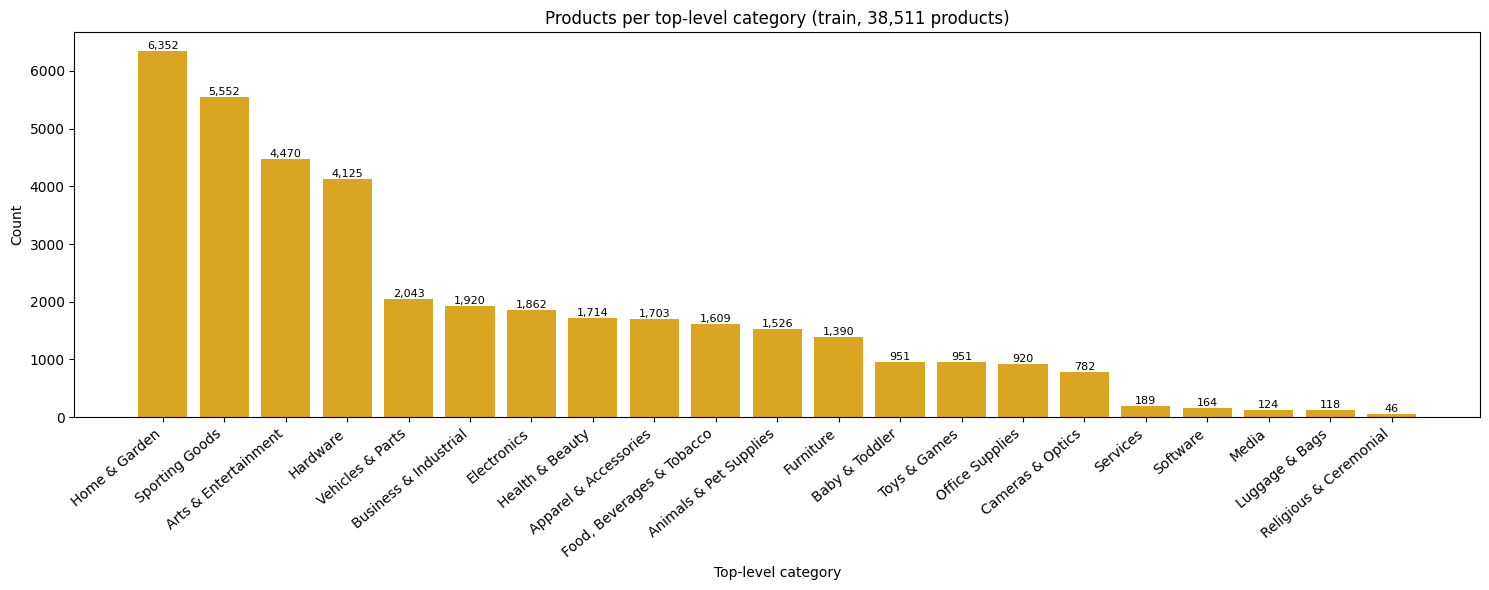

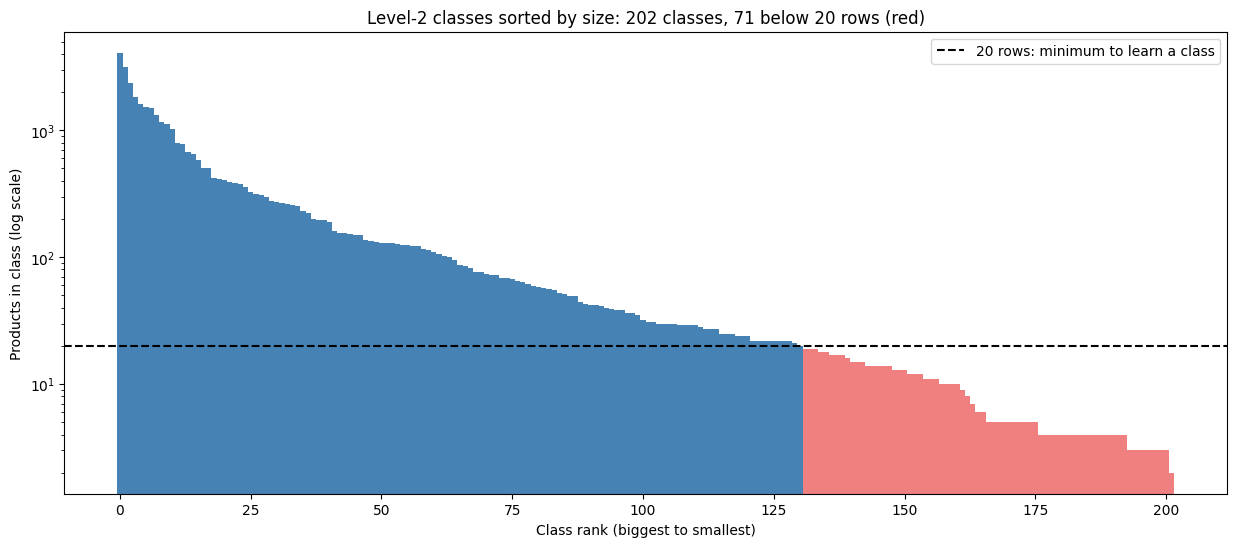

Biggest 5 classes:
label
Arts & Entertainment > Hobbies & Creative Arts    4088
Sporting Goods > Outdoor Recreation               3183
Home & Garden > Kitchen & Dining                  2381
Vehicles & Parts > Vehicle Parts & Accessories    1846
Sporting Goods > Athletics                        1598

Smallest 5 classes:
label
Furniture > Ottomans                  3
Electronics > GPS Tracking Devices    3
Luggage & Bags > Tote Bags            3
Hardware > Small Engines              3
Luggage & Bags > Dry Boxes            2


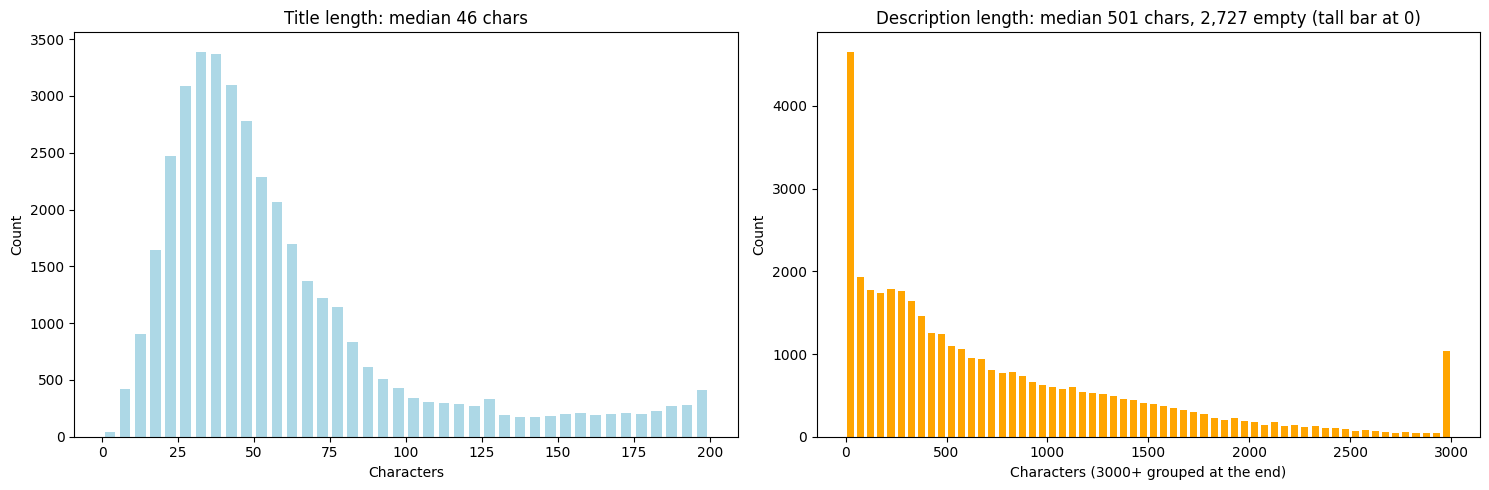

In [4]:
# Cell 4: visualise the label distribution and text lengths (Day 1 style)
import matplotlib.pyplot as plt
import numpy as np

# --- Chart 1: level-1 categories (like Day 1's category bar chart) ---
top_counts = at_level(train["label"], 1).value_counts()
plt.figure(figsize=(15, 6))
plt.bar(top_counts.index, top_counts.values, color="goldenrod")
plt.title(f"Products per top-level category (train, {len(train):,} products)")
plt.xlabel("Top-level category")
plt.ylabel("Count")
plt.xticks(rotation=40, ha="right")
for i, v in enumerate(top_counts.values):
    plt.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

# --- Chart 2: level-2 long tail (the classification version of a skewed price histogram) ---
class_counts = train["label"].value_counts()          # already sorted, biggest first
MIN_ROWS = 20
small = class_counts < MIN_ROWS
plt.figure(figsize=(15, 6))
plt.bar(range(len(class_counts)), class_counts.values,
        color=np.where(small, "lightcoral", "steelblue"), width=1.0)
plt.axhline(MIN_ROWS, color="black", linestyle="--", label=f"{MIN_ROWS} rows: minimum to learn a class")
plt.yscale("log")
plt.title(f"Level-2 classes sorted by size: {len(class_counts)} classes, "
          f"{small.sum()} below {MIN_ROWS} rows (red)")
plt.xlabel("Class rank (biggest to smallest)")
plt.ylabel("Products in class (log scale)")
plt.legend()
plt.show()
print("Biggest 5 classes:")
print(class_counts.head(5).to_string())
print("\nSmallest 5 classes:")
print(class_counts.tail(5).to_string())

# --- Chart 3: text lengths (like Day 1's length histogram) ---
title_len = train["product_title"].str.len()
desc_len = train["product_description"].fillna("").str.len()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].hist(title_len, bins=range(0, 201, 5), rwidth=0.7, color="lightblue")
axes[0].set_title(f"Title length: median {title_len.median():.0f} chars")
axes[0].set_xlabel("Characters"); axes[0].set_ylabel("Count")
axes[1].hist(desc_len.clip(upper=3000), bins=range(0, 3001, 50), rwidth=0.7, color="orange")
axes[1].set_title(f"Description length: median {desc_len.median():.0f} chars, "
                  f"{(desc_len == 0).sum():,} empty (tall bar at 0)")
axes[1].set_xlabel("Characters (3000+ grouped at the end)"); axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()


### What the Step 2 charts show
- **Top-level imbalance:** Home & Garden 6,352 vs Religious & Ceremonial 46 (~138x). The top 4 categories hold over half the data.
- **Long tail:** biggest level-2 class 4,088 (Hobbies & Creative Arts), smallest 2. **71 of 202 classes have under 20 products.** The same shape as Day 1's price skew, on a different axis.
- **Fashion is thin:** `Luggage & Bags > Tote Bags` has 3 products and all of Apparel & Accessories is 4.4%. The synthetic StyleSense catalogue hid this.
- **Titles:** median 46 chars. Unexplained rise near 200 chars (possible platform title limit, to check).
- **Descriptions:** median 501 chars, 2,727 empty, 1,000+ over 3,000 chars. Fine-tuning is billed per token, so long descriptions get truncated in Step 4.

Planned for Step 4: keep empty-description rows (title carries the signal), truncate descriptions, drop classes under 20, cap giant classes.

## Step 3: Leakage, duplicates, and train/test overlap

Three questions, each one a way the final model could look better than it really is:

1. **Leakage:** does `potential_product_categories` already contain the answer? If so, a model given that column learns to copy, not to understand.
2. **Duplicates:** are the same products listed more than once? (Day 1, cell 23.) Also: does the *same* product appear with *different* labels? That's label noise.
3. **Train/test overlap:** do test products also appear in train? If yes, test scores measure memory, not skill.

Texts are **normalized** first (lowercase, trimmed, single spaces), so `"USB Cable "` and `"usb cable"` count as the same. Day 1 only caught exact matches.

1) LEAKAGE (train)
   Full path is one of the candidates:            100.0%
   Level-2 answer appears among candidates:       100.0%
   Candidates point ONLY to the right answer:     23.5%
   Average number of candidates per product:      8.3

2) DUPLICATES (train)
   Repeated titles:                               86
   Repeated non-empty descriptions:               210
   Repeated title + description (exact product):  26
   Titles that appear with DIFFERENT labels:      7

3) TRAIN/TEST OVERLAP
   Test products identical to a train product:    14  (0.1% of test)
   Test titles that also appear in train:         41  (0.4% of test)


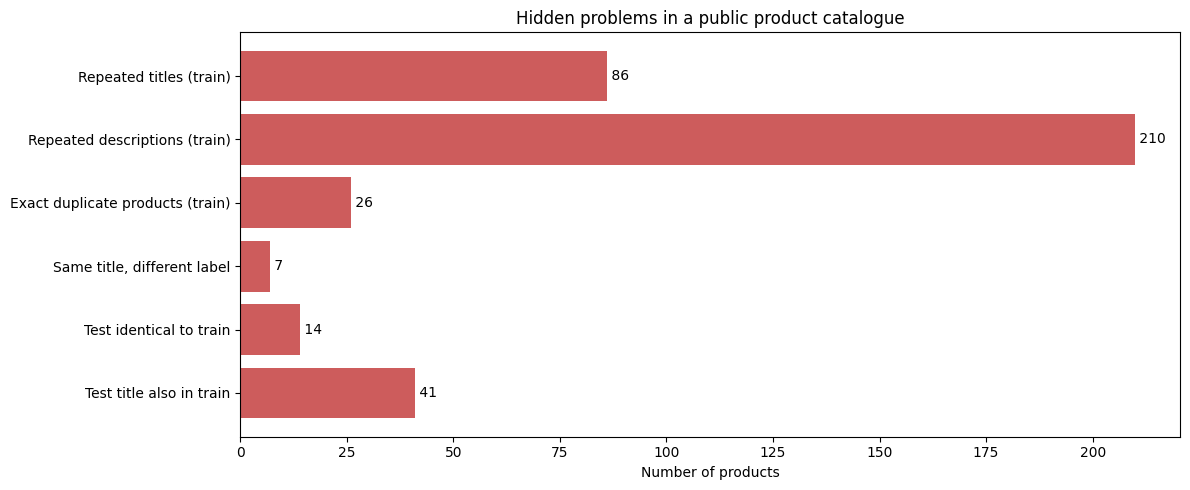


Title: classic
  Labels: ['Office Supplies > General Office Supplies', 'Business & Industrial > Medical']

Title: example product
  Labels: ['Electronics > Electronics Accessories', 'Hardware > Building Materials', 'Sporting Goods > Fitness & General Exercise Equipment']

Title: flag organizer
  Labels: ['Home & Garden > Household Supplies', 'Home & Garden > Decor']


In [5]:
# Cell 5: leakage, duplicates and train/test overlap (measure only; nothing is removed yet)

def norm(s: pd.Series) -> pd.Series:
    """Lowercase, trim, collapse whitespace, so near-identical text matches."""
    return s.fillna("").str.lower().str.strip().str.replace(r"\s+", " ", regex=True)

for df in (train, test):
    df["title_key"] = norm(df["product_title"])
    df["desc_key"] = norm(df["product_description"])
    df["text_key"] = df["title_key"] + " || " + df["desc_key"]

# ---------- 1) Leakage: is the answer already in the candidate list? ----------
def candidate_check(row) -> pd.Series:
    cands = [str(c) for c in row["potential_product_categories"]]
    lvl2 = row["label"]
    cand_lvl2 = {" > ".join(c.split(" > ")[:LEVEL]) for c in cands}   # candidates cut to level 2
    return pd.Series({
        "full_path_in_candidates": row["ground_truth_category"] in cands,
        "label_in_candidates": lvl2 in cand_lvl2,
        "only_option_is_answer": cand_lvl2 == {lvl2},   # every candidate points to the right answer
    })

leak = train.apply(candidate_check, axis=1)
print("1) LEAKAGE (train)")
print(f"   Full path is one of the candidates:            {leak['full_path_in_candidates'].mean():.1%}")
print(f"   Level-2 answer appears among candidates:       {leak['label_in_candidates'].mean():.1%}")
print(f"   Candidates point ONLY to the right answer:     {leak['only_option_is_answer'].mean():.1%}")
print(f"   Average number of candidates per product:      "
      f"{train['potential_product_categories'].apply(len).mean():.1f}")

# ---------- 2) Duplicates inside train ----------
has_desc = train["desc_key"] != ""
dup_title = train["title_key"].duplicated().sum()
dup_desc = train.loc[has_desc, "desc_key"].duplicated().sum()     # ignore empties: they'd all "match"
dup_both = train["text_key"].duplicated().sum()

# Same title, different labels = label noise
labels_per_title = train.groupby("title_key")["label"].nunique()
conflicting_titles = (labels_per_title > 1).sum()

print("\n2) DUPLICATES (train)")
print(f"   Repeated titles:                               {dup_title:,}")
print(f"   Repeated non-empty descriptions:               {dup_desc:,}")
print(f"   Repeated title + description (exact product):  {dup_both:,}")
print(f"   Titles that appear with DIFFERENT labels:      {conflicting_titles:,}")

# ---------- 3) Train/test overlap ----------
train_text, train_titles = set(train["text_key"]), set(train["title_key"])
test_same_text = test["text_key"].isin(train_text).sum()
test_same_title = test["title_key"].isin(train_titles).sum()
print("\n3) TRAIN/TEST OVERLAP")
print(f"   Test products identical to a train product:    {test_same_text:,}  ({test_same_text/len(test):.1%} of test)")
print(f"   Test titles that also appear in train:         {test_same_title:,}  ({test_same_title/len(test):.1%} of test)")

# ---------- Chart: one picture of all the problems ----------
findings = {
    "Repeated titles (train)": dup_title,
    "Repeated descriptions (train)": dup_desc,
    "Exact duplicate products (train)": dup_both,
    "Same title, different label": conflicting_titles,
    "Test identical to train": test_same_text,
    "Test title also in train": test_same_title,
}
plt.figure(figsize=(12, 5))
plt.barh(list(findings.keys()), list(findings.values()), color="indianred")
for i, v in enumerate(findings.values()):
    plt.text(v, i, f" {v:,}", va="center")
plt.gca().invert_yaxis()
plt.title("Hidden problems in a public product catalogue")
plt.xlabel("Number of products")
plt.tight_layout()
plt.show()

# Show a few real examples of label conflicts (read real rows, always)
examples = labels_per_title[labels_per_title > 1].index[:3]
for t in examples:
    print(f"\nTitle: {t[:80]}")
    print("  Labels:", train.loc[train["title_key"] == t, "label"].unique().tolist())


### Step 3 findings

**1. The candidate column gives the answer away, every time.**
- The full correct path is among the candidates in **100%** of products.
- In **23.5%**, every candidate points to the same (correct) level-2 class: the answer is handed over outright.
- This is by design: the dataset is built for a *pick-from-the-list* task (~8 candidates each). That's a much easier task than *read the product and name the category*.
- **Decision: the candidates column is never part of the model's input.** Same dataset, two different tasks; know which one you're measuring.

**2. Duplicates are rare. My prediction was wrong.** Only 26 exact duplicate products (0.07%). Shopify's data is far cleaner than Amazon's here.
- 210 repeated descriptions are mostly **boilerplate shared across different products** (e.g. store-wide text), not duplicate products. Keep them.

**3. Train/test overlap is tiny:** 14 identical products (0.1% of test). The published split is clean.

**4. Conflicting labels come from placeholder products.** Titles like `example product` and `classic` appear with 2 to 3 different labels. These look like store template/demo items, not real products. **Drop them.**

Lesson: measure, don't assume. The expected headline (duplicates) turned out to be small. The real one was the candidate column.

## Step 4: Clean, build the model text, and rebalance

Everything measured so far is now applied, in this order (order matters, as on Day 1):

1. **Merge** train + test, so cleaning rules apply the same way everywhere. We re-split in Step 5.
2. **Drop conflicting / placeholder titles** (same title, different labels).
3. **Shuffle, then deduplicate** exact products. Shuffle first so which copy survives is random (Day 1, cell 23).
4. **Build the model text:** title + description truncated to `MAX_DESC_CHARS`. Empty descriptions are kept (the title carries the signal). Truncation keeps fine-tuning token costs down.
5. **Drop classes under 20 products.** Too few examples to learn. Done *after* dedup because dedup changes the counts.
6. **Cap giant classes** at `MAX_PER_CLASS`. This is the classification version of Day 1's weighted sampling (cell 27): big classes are undersampled so they can't dominate.

Descriptions truncated at 1000 chars: 28.1%
Classes: 202 -> 141
Biggest class share: 10.6% before cap -> 2.0% after cap
Biggest / smallest class: 5062 / 20 before cap -> 500 / 20 after cap

Funnel:
  raw_train                 38,631
  raw_test                   9,658
  labelled_train            38,511
  labelled_test              9,624
  merged                    48,135
  no_conflicting_titles     48,106
  deduplicated              48,074
  classes_20plus            47,550
  capped                    25,023


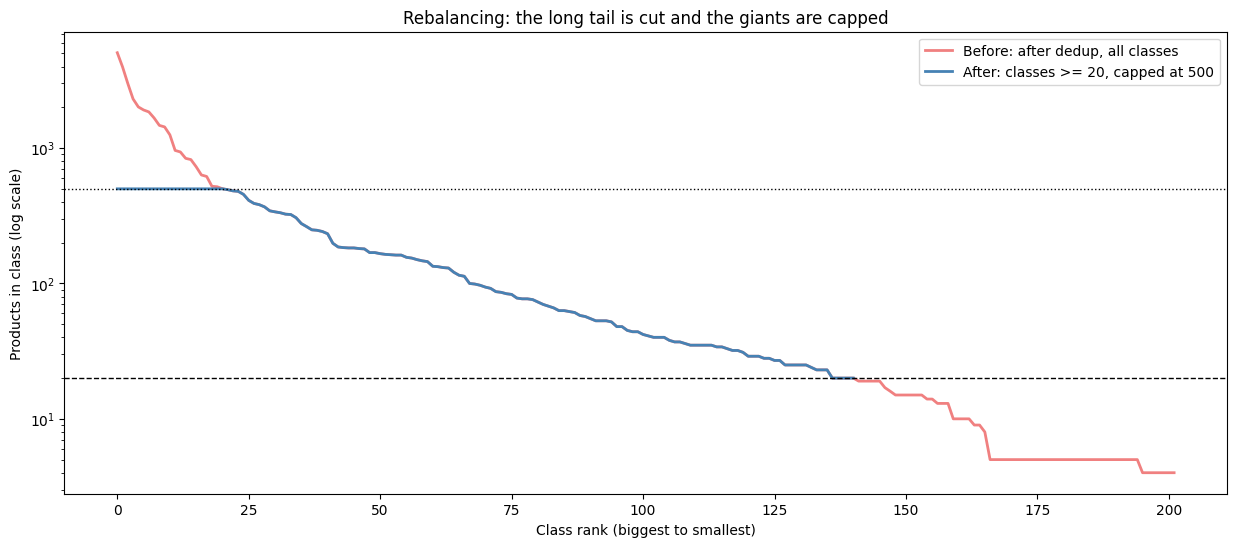

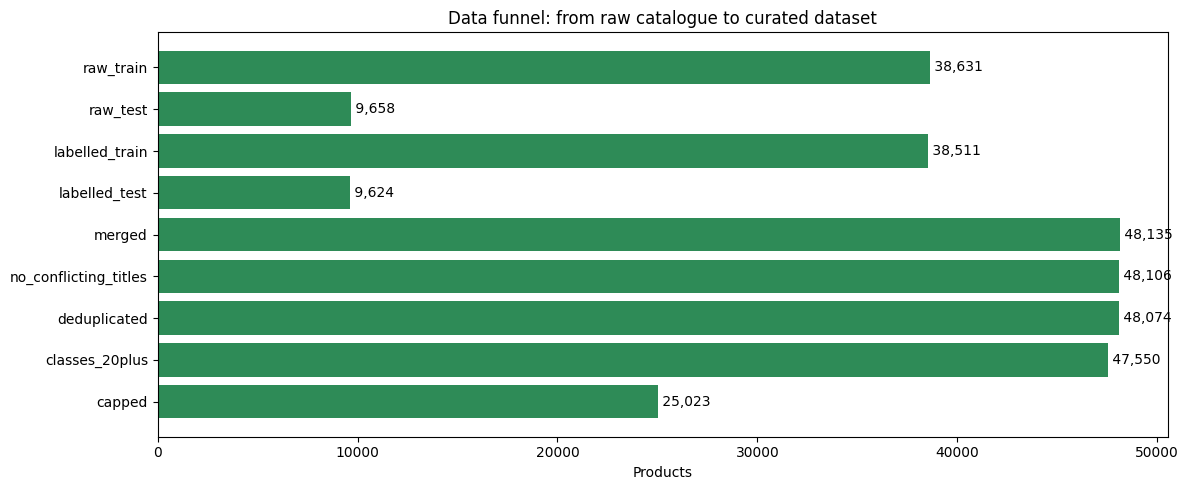


LABEL: Sporting Goods > Fitness & General Exercise Equipment
TEXT:  Foam Balance Pad(Large or XL),5BILLION Stability Pad for Physical Therapy,Non-Slip Exercise Balance Pad for Balance workouts,Yoga Knee Pad for Gym Fitness Stretching Pilate
About This IMPROVE BALANCE and STRENGTH - The exercise mat is made of high qu

LABEL: Apparel & Accessories > Clothing
TEXT:  NOOYME Thermal Underwear Long Johns for Men - Long Underwear Base Layer for Cold Weather
About This Enhance Your Warmth - Crafted from high-quality materials including 29% polyester, 65% nylon, and 6% elastane, NOOYME thermal underwear for men excels

LABEL: Business & Industrial > Science & Laboratory
TEXT:  562. BURETA PARA REDUTEC EN VIDRIO BOROSILICATO 50ML CON GRIFO STOP-FLOW TECNAL
"PRECIOS EXCLUSIVOS ONLINE" PRECIO MÁS IVA. IMAGEN ILUSTRATIVA, PARA MÁS INFORMACIÓN CONTÁCTANOS A TRAVÉS DE NUESTRO CORREO [email]


In [6]:
# Cell 6: apply the cleaning decisions, build the text, rebalance
MAX_DESC_CHARS = 1000   # median description is ~500 chars; 1000 keeps most in full
MIN_PER_CLASS = 20      # below this a class can't be learned (Step 2)
MAX_PER_CLASS = 500     # cap giants so no class dominates
SEED = 42

# 1) Merge both splits (we re-split cleanly in Step 5)
df = pd.concat([train.assign(orig_split="train"), test.assign(orig_split="test")], ignore_index=True)
funnel["merged"] = len(df)

# 2) Drop placeholder / conflicting titles (same title, different labels)
labels_per_title = df.groupby("title_key")["label"].nunique()
bad_titles = set(labels_per_title[labels_per_title > 1].index)
df = df[~df["title_key"].isin(bad_titles)]
funnel["no_conflicting_titles"] = len(df)

# 3) Shuffle, then remove exact duplicate products (normalized title + description)
df = df.sample(frac=1, random_state=SEED)
df = df.drop_duplicates(subset="text_key")
funnel["deduplicated"] = len(df)

# 4) Build the text the model will read: title + (truncated) description. Candidates are NOT included.
desc = df["product_description"].fillna("").str.strip()
share_truncated = (desc.str.len() > MAX_DESC_CHARS).mean()
df["text"] = df["product_title"].str.strip() + np.where(desc != "", "\n" + desc.str[:MAX_DESC_CHARS], "")

# 5) Drop classes that are too small to learn
counts_before = df["label"].value_counts()
keep_classes = counts_before[counts_before >= MIN_PER_CLASS].index
df = df[df["label"].isin(keep_classes)]
funnel["classes_20plus"] = len(df)
counts_mid = df["label"].value_counts()

# 6) Cap giant classes (df is already shuffled, so head() is a random sample per class)
df = df.groupby("label", group_keys=False).head(MAX_PER_CLASS)
funnel["capped"] = len(df)
counts_after = df["label"].value_counts()

print(f"Descriptions truncated at {MAX_DESC_CHARS} chars: {share_truncated:.1%}")
print(f"Classes: {counts_before.size} -> {counts_after.size}")
print(f"Biggest class share: {counts_mid.iloc[0] / counts_mid.sum():.1%} before cap -> "
      f"{counts_after.iloc[0] / counts_after.sum():.1%} after cap")
print(f"Biggest / smallest class: {counts_mid.iloc[0]} / {counts_mid.iloc[-1]} before cap -> "
      f"{counts_after.iloc[0]} / {counts_after.iloc[-1]} after cap")
print("\nFunnel:")
for step, n in funnel.items():
    print(f"  {step:24} {n:>7,}")

# --- Chart 1: class sizes before vs after rebalancing (Day 1 cells 25 vs 28, for classes) ---
plt.figure(figsize=(15, 6))
plt.plot(range(len(counts_before)), counts_before.values, color="lightcoral", linewidth=2,
         label="Before: after dedup, all classes")
plt.plot(range(len(counts_after)), counts_after.sort_values(ascending=False).values, color="steelblue",
         linewidth=2, label=f"After: classes >= {MIN_PER_CLASS}, capped at {MAX_PER_CLASS}")
plt.axhline(MIN_PER_CLASS, color="black", linestyle="--", linewidth=1)
plt.axhline(MAX_PER_CLASS, color="black", linestyle=":", linewidth=1)
plt.yscale("log")
plt.title("Rebalancing: the long tail is cut and the giants are capped")
plt.xlabel("Class rank (biggest to smallest)")
plt.ylabel("Products in class (log scale)")
plt.legend()
plt.show()

# --- Chart 2: the data funnel (every step's count, for the README and post) ---
steps = list(funnel.keys())
values = list(funnel.values())
plt.figure(figsize=(12, 5))
plt.barh(steps, values, color="seagreen")
for i, v in enumerate(values):
    plt.text(v, i, f" {v:,}", va="center")
plt.gca().invert_yaxis()
plt.title("Data funnel: from raw catalogue to curated dataset")
plt.xlabel("Products")
plt.tight_layout()
plt.show()

# Read a few real final examples
for _, r in df.sample(3, random_state=SEED).iterrows():
    print(f"\nLABEL: {r['label']}\nTEXT:  {r['text'][:250]}")


### Step 4 findings
- **Rebalancing was the biggest cut by far:** 47,550 -> 25,023 (47% removed). Biggest class share fell from 10.6% to 2.0%, and 141 classes remain.
- **Tradeoff, stated honestly:** half the data is discarded to balance classes, and the resulting test set is balanced too, so its scores won't reflect the real catalogue's mix (same tradeoff as Day 1's weighted sampling). For a lite fine-tuning set this is the right call. A production classifier would keep all the data and use class weights instead.
- 28.1% of descriptions were truncated at 1,000 chars.

Reading the final examples surfaced three new problems no chart showed:
1. **Contact details in a public dataset:** one product contains a real business email address. Before publishing a dataset, scrub emails, URLs and phone numbers.
2. **Not all English:** a Spanish laboratory product. Language is a hidden variable. Measure it.
3. **Scraping leftovers:** descriptions starting with "About This", and keyword-stuffed marketplace titles (likely behind the bump near 200 chars in the title histogram).

### Step 4b: Text hygiene before publishing

Publishing a dataset is a responsibility, not just an upload. This cell:
1. **Counts, then removes** emails, URLs and phone-like numbers (with real examples printed, so false positives are visible).
2. Strips the "About this item" scraping prefix.
3. **Estimates** how much text isn't English, using a simple common-word heuristic (a rough estimate, not a language detector).

emails: 283 products
   e.g. ['[email]']
   e.g. ['[email]']
   e.g. ['[email]']
urls: 300 products
   e.g. ['[url]', '[url]']
   e.g. ['[url]']
   e.g. ['[url]']
phone-like numbers: 1,813 products
   e.g. ['5337020450207515']
   e.g. ['4 2008-2009']
   e.g. ['26-29 32.25', '28-31 32.5']
'About this' prefix: 1,071 products

Likely Spanish (rough): 2,219 (8.9%)
No common English words (rough): 8,075 (32.3%)
Example 'no English' texts:
    Spinta 555765
    Passette à double embouts - Ashford | Passette à double embouts fabriquée à partir de nylon solide et flexible.
    Pr-24-pc - Bastón Pr-24 De Policarbonato | TONFA BASTON PR 24 DE POLICARBONATO CON PORTA TONFA DE ARO LARGO TOTAL 62 CMS L


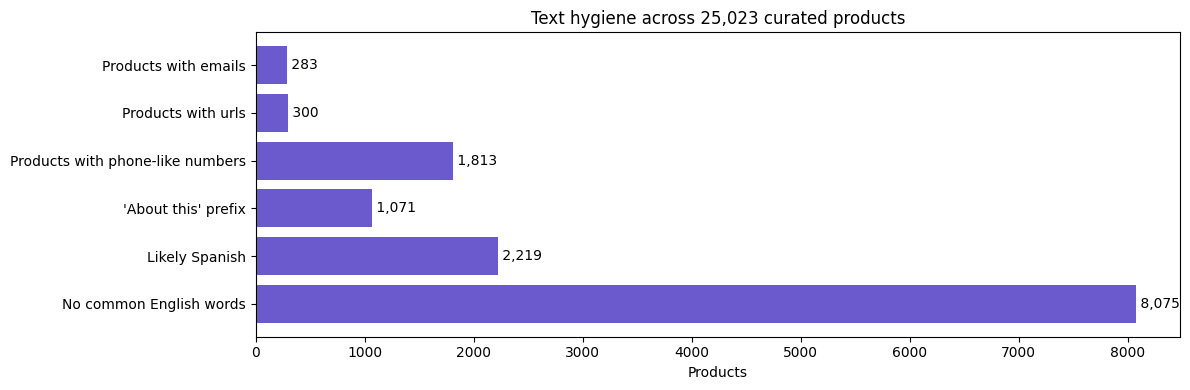

In [7]:
# Cell 7: scrub contact details, strip scraping leftovers, estimate language mix
import re

EMAIL = r"[\w.+-]+@[\w-]+\.[\w.-]+"
URL = r"(?:https?://\S+|www\.\S+)"
PHONE = r"\+?\d[\d\s().-]{8,}\d"          # 10+ digits with separators
ABOUT_PREFIX = r"(?im)^about this(?: item)?\s*"

# 1) Count and show real examples BEFORE removing anything
hygiene = {}
for name, pattern in [("emails", EMAIL), ("urls", URL), ("phone-like numbers", PHONE)]:
    has = df["text"].str.contains(pattern, regex=True)
    hygiene[f"Products with {name}"] = int(has.sum())
    print(f"{name}: {has.sum():,} products")
    for m in df.loc[has, "text"].str.findall(pattern).head(3):
        print("   e.g.", m[:2])

has_about = df["text"].str.contains(ABOUT_PREFIX, regex=True)
hygiene["'About this' prefix"] = int(has_about.sum())
print(f"'About this' prefix: {has_about.sum():,} products")

# 2) Remove them
clean = df["text"]
for pattern, repl in [(EMAIL, "[email]"), (URL, "[url]"), (PHONE, "[phone]"), (ABOUT_PREFIX, "")]:
    clean = clean.str.replace(pattern, repl, regex=True)
df["text"] = clean.str.replace(r"[ \t]+", " ", regex=True).str.strip()

# 3) Rough language estimate: which common words dominate?
lower = df["text"].str.lower()
en_words = lower.str.count(r"\b(?:the|and|for|with|this|your|from|is)\b")
es_words = lower.str.count(r"\b(?:para|con|del|los|las|una|por|el|la|en|y)\b")
likely_spanish = es_words > en_words
no_english = en_words == 0
hygiene["Likely Spanish"] = int(likely_spanish.sum())
hygiene["No common English words"] = int(no_english.sum())
print(f"\nLikely Spanish (rough): {likely_spanish.sum():,} ({likely_spanish.mean():.1%})")
print(f"No common English words (rough): {no_english.sum():,} ({no_english.mean():.1%})")
print("Example 'no English' texts:")
for t in df.loc[no_english, "text"].head(3):
    print("   ", t[:120].replace("\n", " | "))

# Chart: what text hygiene found
plt.figure(figsize=(12, 4))
plt.barh(list(hygiene.keys()), list(hygiene.values()), color="slateblue")
for i, v in enumerate(hygiene.values()):
    plt.text(v, i, f" {v:,}", va="center")
plt.gca().invert_yaxis()
plt.title(f"Text hygiene across {len(df):,} curated products")
plt.xlabel("Products")
plt.tight_layout()
plt.show()


### Step 4b findings: the cleaning rule was wrong

- **Emails (283) and URLs (300) were real contact details and API links.** Correct to remove.
- **The phone rule was badly wrong.** Its "matches" were a product ID (`5337020450207515`), years (`2008-2009`) and **clothing size ranges** (`26-29 32.25`). It deleted real product information from 1,813 products, including sizes, exactly the attributes a stylist needs.
- This is the Day 1 regex bug again: **a cleaning rule is a hypothesis until you've read what it matched.** Printing examples before trusting the counts is what caught it.
- **Language:** ~8.9% likely Spanish, and French is present too. The "no common English words" figure (32%) is **not a language measure**: it's inflated by short title-only texts like `Spinta 555765`. Reported as a heuristic limitation, not a finding.
- **Decision on language: keep all languages.** Real catalogues are multilingual, frontier models handle it, and dropping them would bias the dataset toward English-speaking stores. Documented in the dataset card.

Fix (next cell): rebuild the text from the original columns, then apply only the rules that proved safe, plus a **strict** phone rule that requires a phone keyword (`tel`, `phone`, `call`...).

In [8]:
# Cell 8: rebuild the text from the original columns and re-apply only SAFE cleaning rules
PHONE_STRICT = r"(?i)\b(?:tel|phone|call|whatsapp|mobile|tlf|tel[eé]fono)\b[^\d\n]{0,12}\+?\(?\d[\d\s().-]{7,}\d"

# 1) Rebuild from source columns (undo the damage from cell 7)
desc = df["product_description"].fillna("").str.strip()
df["text"] = df["product_title"].str.strip() + np.where(desc != "", "\n" + desc.str[:MAX_DESC_CHARS], "")

# 2) Check the strict phone rule BEFORE applying it
has_phone = df["text"].str.contains(PHONE_STRICT, regex=True)
print(f"Strict phone rule matches: {has_phone.sum():,} products")
for m in df.loc[has_phone, "text"].str.findall(PHONE_STRICT).head(5):
    print("   e.g.", m[:2])

# 3) Apply the safe rules
clean = df["text"]
for pattern, repl in [(EMAIL, "[email]"), (URL, "[url]"), (PHONE_STRICT, "[phone]"), (ABOUT_PREFIX, "")]:
    clean = clean.str.replace(pattern, repl, regex=True)
df["text"] = clean.str.replace(r"[ \t]+", " ", regex=True).str.strip()

# 4) Verify: sizes and years survived, contact details are gone
SIZE_RANGE = r"\b\d{2}-\d{2}\b"
sizes_kept = df["text"].str.contains(SIZE_RANGE, regex=True).sum()
emails_left = df["text"].str.contains(EMAIL, regex=True).sum()
urls_left = df["text"].str.contains(URL, regex=True).sum()
print(f"\nTexts still containing size ranges like '26-29': {sizes_kept:,}")
print(f"Emails left: {emails_left} | URLs left: {urls_left}")

funnel["final"] = len(df)
print(f"\nFinal curated products: {len(df):,} across {df['label'].nunique()} classes")


Strict phone rule matches: 74 products
   e.g. ['Phone: [phone]']
   e.g. ['call Chris at [phone]']
   e.g. ['call us at [phone]']
   e.g. ['call us at [phone]']
   e.g. ['Call [phone]']

Texts still containing size ranges like '26-29': 565
Emails left: 0 | URLs left: 0

Final curated products: 25,023 across 141 classes


### Step 4c result
- The strict phone rule matched **74** products, all real phone numbers (e.g. `call us at [phone]`). The loose rule had matched **1,813**, about 25x over-matching.
- 565 texts still contain size ranges (sizes survived). 0 emails and 0 URLs remain.
- **Final curated dataset: 25,023 products, 141 classes.**

## Step 5: Stratified split, then publish

**Stratified** means every class gets its fair share in train, validation and test (10% each for val and test, minimum 2 per class).
A plain random split could leave a small 20-product class with zero test examples, so we could never measure it.

We split **after** all cleaning and deduplication, so no product can land in two splits (Day 1: dedup first, split second).

Published columns: `text` (model input), `label` (level-2 category), `full_category` (the original full path).
**Not published as input:** `potential_product_categories`, because it contains the answer (Step 3).

train       20,027 rows | 141 classes
validation   2,498 rows | 141 classes
test         2,498 rows | 141 classes

Validation texts also in train: 0
Test texts also in train:       1


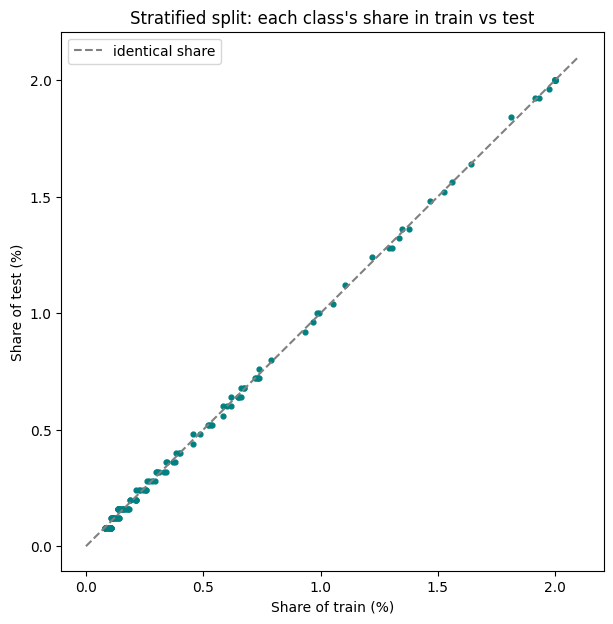


Saved: data/train.parquet, data/validation.parquet, data/test.parquet, funnel.json


In [9]:
# Cell 9: stratified split, leakage check, save locally
import json
from pathlib import Path

VAL_FRAC, TEST_FRAC = 0.10, 0.10

df = df.sample(frac=1, random_state=SEED).reset_index(drop=True)
rank = df.groupby("label").cumcount()                         # position inside its class (random order)
size = df.groupby("label")["label"].transform("size")         # class size, on every row
n_test = np.maximum(2, np.round(size * TEST_FRAC)).astype(int)
n_val = np.maximum(2, np.round(size * VAL_FRAC)).astype(int)
df["split"] = np.where(rank < n_test, "test", np.where(rank < n_test + n_val, "validation", "train"))

out = df[["text", "label", "ground_truth_category", "split"]].rename(columns={"ground_truth_category": "full_category"})
splits = {s: out[out["split"] == s].drop(columns="split").reset_index(drop=True)
          for s in ["train", "validation", "test"]}

for s, d in splits.items():
    print(f"{s:11} {len(d):>6,} rows | {d['label'].nunique()} classes")

# Leakage check on the FINAL splits: no text may appear in two splits
train_texts = set(splits["train"]["text"])
print(f"\nValidation texts also in train: {splits['validation']['text'].isin(train_texts).sum()}")
print(f"Test texts also in train:       {splits['test']['text'].isin(train_texts).sum()}")

# Chart: every class should have the same share in train and test (points on the diagonal)
share_train = splits["train"]["label"].value_counts(normalize=True)
share_test = splits["test"]["label"].value_counts(normalize=True).reindex(share_train.index, fill_value=0)
plt.figure(figsize=(7, 7))
plt.scatter(share_train * 100, share_test * 100, s=12, color="teal")
lim = max(share_train.max(), share_test.max()) * 100 * 1.05
plt.plot([0, lim], [0, lim], "--", color="gray", label="identical share")
plt.title("Stratified split: each class's share in train vs test")
plt.xlabel("Share of train (%)")
plt.ylabel("Share of test (%)")
plt.legend()
plt.show()

# Save locally (parquet, one file per split) + the funnel for the README
Path("data").mkdir(exist_ok=True)
for s, d in splits.items():
    d.to_parquet(f"data/{s}.parquet", index=False)
funnel["train"], funnel["validation"], funnel["test"] = (len(splits[s]) for s in ["train", "validation", "test"])
with open("funnel.json", "w") as f:
    json.dump({k: int(v) for k, v in funnel.items()}, f, indent=2)
print("\nSaved: data/train.parquet, data/validation.parquet, data/test.parquet, funnel.json")


### Step 5b: remove the one cross-split leak

Cell 9 found **1 test text that also appears in train**. Deduplication (Step 4) ran *before* text hygiene and truncation,
so two products that differed only in an email, a URL or text beyond 1,000 characters became identical *after* cleaning.

Lesson: **re-check duplicates after any step that changes the text.** The fix: drop the leaked row from test (train stays untouched), re-save, and re-publish.

In [10]:
# Cell 9b: remove test rows whose text also appears in train, then re-save
leaked = splits["test"]["text"].isin(train_texts)
print(f"Leaked test rows: {leaked.sum()}")
for t in splits["test"].loc[leaked, "text"]:
    print("   ", t[:200].replace("\n", " | "))

splits["test"] = splits["test"][~leaked].reset_index(drop=True)
splits["validation"] = splits["validation"][~splits["validation"]["text"].isin(train_texts)].reset_index(drop=True)

# Re-verify: must be 0 and 0
print(f"\nValidation texts also in train: {splits['validation']['text'].isin(train_texts).sum()}")
print(f"Test texts also in train:       {splits['test']['text'].isin(train_texts).sum()}")

for s, d in splits.items():
    d.to_parquet(f"data/{s}.parquet", index=False)
funnel["validation"], funnel["test"] = len(splits["validation"]), len(splits["test"])
with open("funnel.json", "w") as f:
    json.dump({k: int(v) for k, v in funnel.items()}, f, indent=2)
print(f"\nSaved. train {len(splits['train']):,} | validation {len(splits['validation']):,} | test {len(splits['test']):,}")


Leaked test rows: 1
    Versare Hush Panel Cubicle Kit | Workstation Partition Walls | Sound Dampening Cubicle Walls | Partitions for Desks | MULTIPLE CONFIGURATIONS: Use these Hush Panel Cubicle Kits as the building block of 

Validation texts also in train: 0
Test texts also in train:       0

Saved. train 20,027 | validation 2,498 | test 2,497


### Publish to Hugging Face

The repo is created **private** first. Open it, read the dataset card and preview, then switch it to public in the repo settings.
Publishing is a one-way door in practice (people can download it the moment it's public), so review before exposing it.

The dataset card documents the source and license (Apache-2.0, same as the source), every curation decision, the funnel, and known limitations.

In [11]:
# Cell 10: write the dataset card and publish (PRIVATE first)
from huggingface_hub import HfApi

api = HfApi()
me = api.whoami()["name"]            # fails if not logged in: run huggingface_hub.login() with your WRITE token
print("Logged in as:", me)
REPO_ID = f"{me}/shopify_category_lite"
PRIVATE = True                        # review on the website, then make it public in Settings

facts = {
    "repo": REPO_ID,
    "raw": funnel["raw_train"] + funnel["raw_test"],
    "final": funnel["final"],
    "n_train": funnel["train"], "n_val": funnel["validation"], "n_test": funnel["test"],
    "n_classes": splits["train"]["label"].nunique(),
    "leak_full": f"{leak['full_path_in_candidates'].mean():.0%}",
    "leak_only": f"{leak['only_option_is_answer'].mean():.1%}",
    "dups": funnel["no_conflicting_titles"] - funnel["deduplicated"],
    "conflict_titles": len(bad_titles),
    "conflict_rows": funnel["merged"] - funnel["no_conflicting_titles"],
    "emails": hygiene["Products with emails"], "urls": hygiene["Products with urls"],
    "phones": int(has_phone.sum()), "loose_phones": f"{hygiene['Products with phone-like numbers']:,}",
    "min_c": MIN_PER_CLASS, "max_c": MAX_PER_CLASS, "max_desc": MAX_DESC_CHARS,
    "funnel": "\n".join(f"| {k} | {v:,} |" for k, v in funnel.items() if k != "final"),
}

CARD = """---
license: apache-2.0
task_categories:
- text-classification
language:
- en
- es
- fr
size_categories:
- 10K<n<100K
source_datasets:
- Shopify/product-catalogue
pretty_name: Shopify Product Category (curated lite)
configs:
- config_name: default
  data_files:
  - split: train
    path: data/train.parquet
  - split: validation
    path: data/validation.parquet
  - split: test
    path: data/test.parquet
---

# Shopify Product Category (curated lite)

A curated, balanced subset of [Shopify/product-catalogue](https://huggingface.co/datasets/Shopify/product-catalogue)
for **product categorisation from text**: read a product's title and description, predict its category.

Built as a learning project applying data-curation practice (funnel tracking, label design, leakage checks,
deduplication, rebalancing, text hygiene) to a real public catalogue.

## Task and columns

| Column | Meaning |
|---|---|
| `text` | Model input: product title + description (description truncated to {max_desc} chars) |
| `label` | Target: level-2 category, e.g. `Home & Garden > Decor` ({n_classes} classes) |
| `full_category` | The original full category path, for reference |

Splits: **{n_train:,} train / {n_val:,} validation / {n_test:,} test**, stratified by `label`.

## Curation funnel

| Step | Products |
|---|---|
{funnel}

## Decisions

- **Label granularity: level 2.** Level 1 is too broad to be useful; at level 3, 4 out of 5 classes had fewer than 20 products.
- **Removed non-product labels** (`Uncategorized`, `Gift Cards`, `Bundles`, `Product Add-Ons`) and 1-level paths.
- **The source's `potential_product_categories` column is excluded.** It contains the correct full path in {leak_full} of products,
  and in {leak_only} of products every candidate points to the correct level-2 class. Using it turns *name the category* into *pick from a list*.
- **Dropped {conflict_titles} titles that appeared with conflicting labels** ({conflict_rows} products; placeholder items such as `example product`).
- **Deduplicated** on normalised title + description after merging the source splits: {dups} duplicate products removed.
- **Rebalanced:** classes with fewer than {min_c} products dropped; classes capped at {max_c} (random sample).
- **Text hygiene:** removed emails ({emails} products), URLs ({urls}) and phone numbers ({phones}). A first, looser phone rule
  matched {loose_phones} products, mostly sizes, years and IDs, and was replaced with a keyword-anchored rule.
- **Languages kept as-is:** mostly English, roughly 9% Spanish, some French.\n- **Duplicates re-checked after cleaning:** one product became identical to a train product only after text hygiene; it was removed from test. No text appears in more than one split.

## Known limitations

- Capping classes discards about half the usable products and makes test scores reflect a **balanced** catalogue, not the real mix.
- Some source labels are genuinely ambiguous (e.g. an "Airplane Piggy Bank": toy or decor?). This caps achievable accuracy.
- The language estimate is a word-count heuristic, not a language detector.
- About 7% of source descriptions are empty; those products rely on the title alone.

## Source and license

Derived from [Shopify/product-catalogue](https://huggingface.co/datasets/Shopify/product-catalogue), released under Apache-2.0.
This derivative is released under the same license. Images from the source are not included.
""".format(**facts)

Path("dataset_card.md").write_text(CARD)

api.create_repo(REPO_ID, repo_type="dataset", private=PRIVATE, exist_ok=True)
api.upload_folder(folder_path="data", path_in_repo="data", repo_id=REPO_ID, repo_type="dataset")
api.upload_file(path_or_fileobj="dataset_card.md", path_in_repo="README.md", repo_id=REPO_ID, repo_type="dataset")
print(f"\nPublished ({'private' if PRIVATE else 'public'}): https://huggingface.co/datasets/{REPO_ID}")


Logged in as: raghu619


Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

No files have been modified since last commit. Skipping to prevent empty commit.
No files have been modified since last commit. Skipping to prevent empty commit.



Published (private): https://huggingface.co/datasets/raghu619/shopify_category_lite


## Step 6: Save the key charts for the README

GitHub READMEs can't show charts from inside a notebook reliably, so the three charts that tell the story are saved as images.

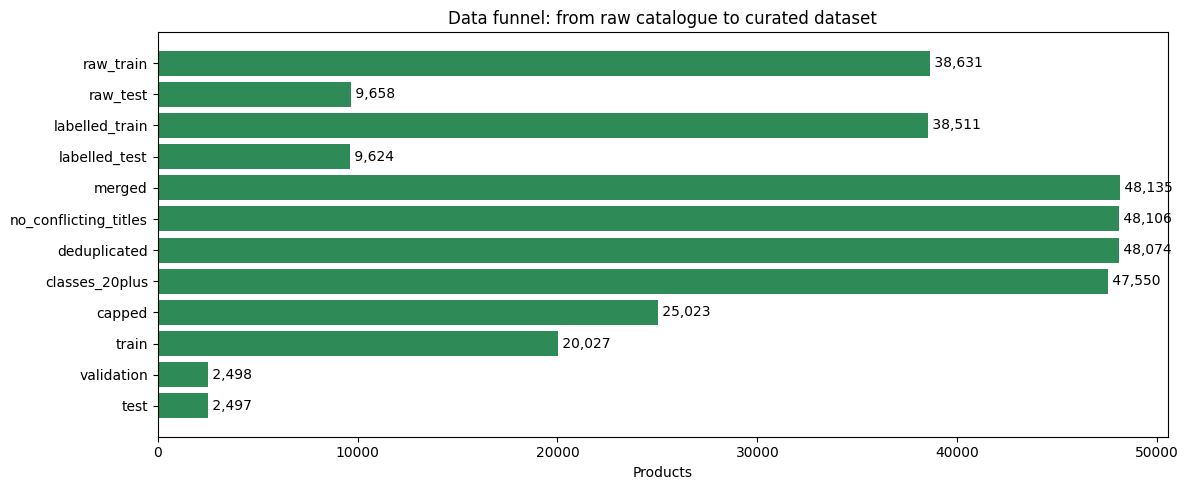

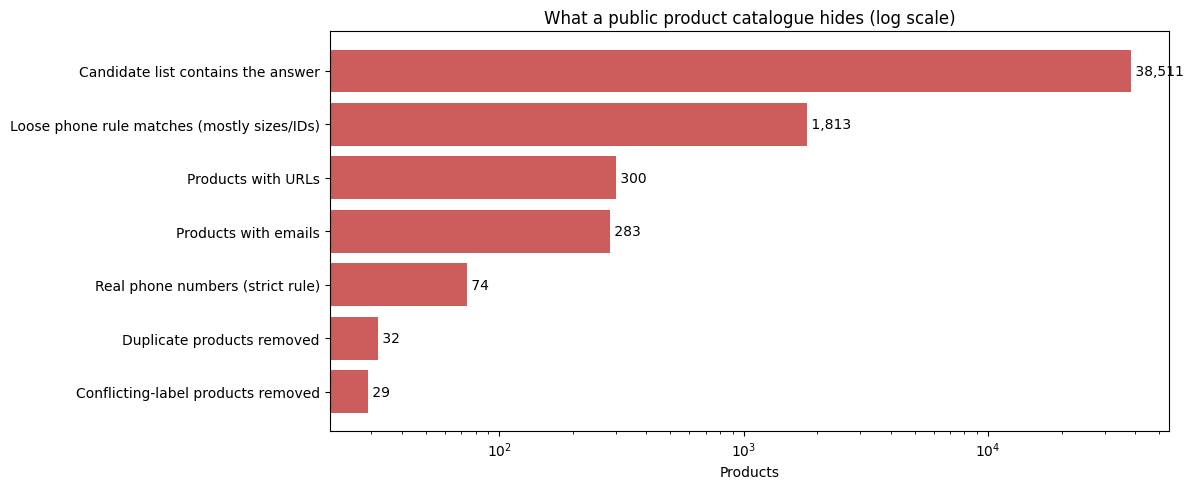

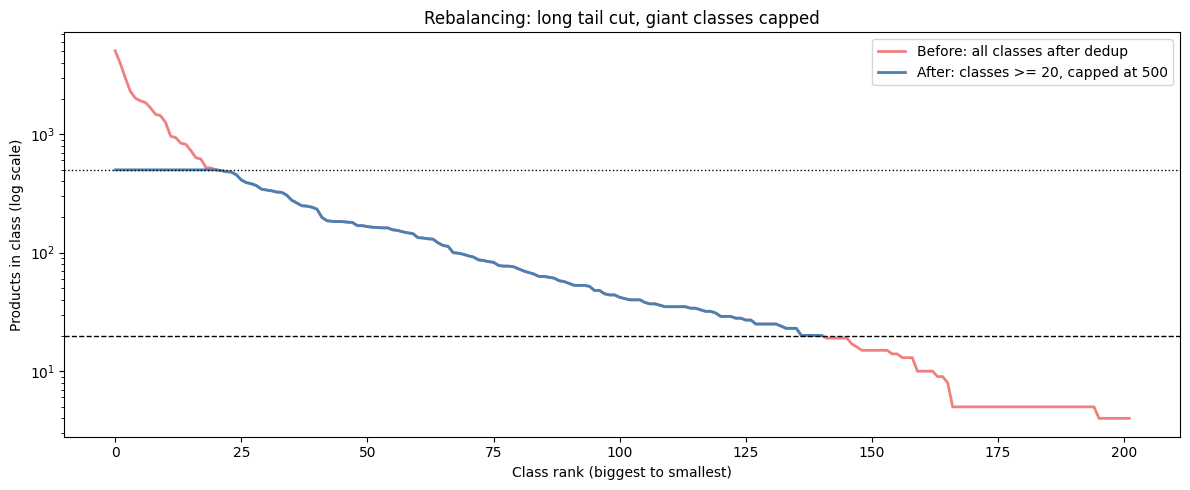

Saved: assets/funnel.png, assets/hidden_problems.png, assets/rebalancing.png


In [12]:
# Cell 11: save the 3 story charts as PNGs for the README
Path("assets").mkdir(exist_ok=True)

# 1) Data funnel
steps = [k for k in funnel if k != "final"]
vals = [funnel[k] for k in steps]
plt.figure(figsize=(12, 5))
plt.barh(steps, vals, color="seagreen")
for i, v in enumerate(vals):
    plt.text(v, i, f" {v:,}", va="center")
plt.gca().invert_yaxis()
plt.title("Data funnel: from raw catalogue to curated dataset")
plt.xlabel("Products")
plt.tight_layout()
plt.savefig("assets/funnel.png", dpi=150)
plt.show()

# 2) Hidden problems found in the source data
problems = {
    "Candidate list contains the answer": int(leak["full_path_in_candidates"].sum()),
    "Loose phone rule matches (mostly sizes/IDs)": hygiene["Products with phone-like numbers"],
    "Products with URLs": hygiene["Products with urls"],
    "Products with emails": hygiene["Products with emails"],
    "Real phone numbers (strict rule)": int(has_phone.sum()),
    "Duplicate products removed": funnel["no_conflicting_titles"] - funnel["deduplicated"],
    "Conflicting-label products removed": funnel["merged"] - funnel["no_conflicting_titles"],
}
plt.figure(figsize=(12, 5))
plt.barh(list(problems.keys()), list(problems.values()), color="indianred")
for i, v in enumerate(problems.values()):
    plt.text(v, i, f" {v:,}", va="center")
plt.gca().invert_yaxis()
plt.xscale("log")
plt.title("What a public product catalogue hides (log scale)")
plt.xlabel("Products")
plt.tight_layout()
plt.savefig("assets/hidden_problems.png", dpi=150)
plt.show()

# 3) Rebalancing: long tail before vs after
plt.figure(figsize=(12, 5))
plt.plot(range(len(counts_before)), counts_before.values, color="lightcoral", linewidth=2, label="Before: all classes after dedup")
plt.plot(range(len(counts_after)), counts_after.sort_values(ascending=False).values, color="steelblue", linewidth=2,
         label=f"After: classes >= {MIN_PER_CLASS}, capped at {MAX_PER_CLASS}")
plt.axhline(MIN_PER_CLASS, color="black", linestyle="--", linewidth=1)
plt.axhline(MAX_PER_CLASS, color="black", linestyle=":", linewidth=1)
plt.yscale("log")
plt.title("Rebalancing: long tail cut, giant classes capped")
plt.xlabel("Class rank (biggest to smallest)")
plt.ylabel("Products in class (log scale)")
plt.legend()
plt.tight_layout()
plt.savefig("assets/rebalancing.png", dpi=150)
plt.show()
print("Saved: assets/funnel.png, assets/hidden_problems.png, assets/rebalancing.png")
